# Phase 3: Research Questions (Issa)
**By:** Mohamed Issa

Two research questions answered from the integrated ZIP x year table `data/zip_year.csv` (written by `phase2_data_integration_issa.ipynb`):

1. **Where is construction growing fastest, and do collisions in those ZIP codes move the same way?**
2. **Does the borough pattern of construction match the borough pattern of collisions over time?**

**Rules used throughout:**
- Comparisons use the **full years 2022 to 2025** only. 2026 covers January to October, so it is left out.
- Rows with `low_data_flag == True` (fewer than 5 collisions **and** fewer than 5 housing jobs in that ZIP-year) are left out; the next cell prints how many.
- "Construction" means housing jobs started, counted from `I1` filings (Walid's definitions). "Collisions" means crashes with a ZIP code.
- Every result is an **association**. Nothing here shows that construction causes collisions, or the reverse.

**How to run:** open the repository in VS Code, select the `.venv` kernel, Restart Kernel and Run All. Each chart is saved to `assets/rq/` together with a one-paragraph finding that the website displays.

These questions do not repeat Ahmed's (new buildings vs the pedestrian and cyclist injury rate by quartile; the contributing-factor profile).

In [1]:
from pathlib import Path

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from matplotlib.colors import TwoSlopeNorm

DATA = Path("data/zip_year.csv")
if not DATA.exists():
    raise FileNotFoundError(
        "data/zip_year.csv not found. It is written by phase2_data_integration_issa.ipynb "
        "and committed on main: run `git pull origin main`, or run that notebook first.")
ASSETS = Path("assets/rq")
ASSETS.mkdir(parents=True, exist_ok=True)

FULL_YEARS = [2022, 2023, 2024, 2025]
START, END = 2022, 2025
BOROUGHS = ["Manhattan", "Brooklyn", "Queens", "Bronx", "Staten Island"]
BOROUGH_COLORS = {"Manhattan": "#4C72B0", "Brooklyn": "#DD8452", "Queens": "#55A868",
                  "Bronx": "#C44E52", "Staten Island": "#8172B3"}

zip_year = pd.read_csv(DATA, dtype={"zip_code": str})
print("zip_year.csv:", zip_year.shape, "| years:", sorted(zip_year["year"].unique()))

full = zip_year[zip_year["year"].isin(FULL_YEARS)]
low = full["low_data_flag"]
data = full[~low].copy()
print(f"Rows in the full years {START}-{END}: {len(full):,}")
print(f"Rows left out with low_data_flag == True: {int(low.sum())}")
print(f"Rows used: {len(data):,} | ZIP codes: {data['zip_code'].nunique()}")
print()

# Quoted from the saved outputs of phase2_collisions_aggregation_yassin.ipynb (on main);
# the crash-level data is not in this repository, so these shares cannot be recomputed here.
MISSING_ZIP_PCT = pd.Series({"all years": 28.25, "2022": 33.83, "2023": 32.01, "2024": 28.63, "2025": 19.98},
                            name="% of crashes with no ZIP (excluded)")
print("Quoted from Yassin's notebook, crashes with no ZIP code (not in zip_year.csv):")
print(MISSING_ZIP_PCT.to_string())


def spearman(x, y):
    """Spearman rho = Pearson correlation of the ranks (ties get the average rank). No scipy needed."""
    return pd.Series(x).rank().corr(pd.Series(y).rank())


def permutation_p(x, y, n_perm=10_000, seed=42):
    """Two-sided permutation p-value for Spearman rho: shuffle y, recompute rho, count |rho*| >= |rho|."""
    rx = pd.Series(x).rank().to_numpy()
    ry = pd.Series(y).rank().to_numpy()
    rx = (rx - rx.mean()) / rx.std()
    ry = (ry - ry.mean()) / ry.std()
    rho = float(np.mean(rx * ry))
    rng = np.random.default_rng(seed)
    perms = np.array([np.mean(rx * rng.permutation(ry)) for _ in range(n_perm)])
    p = (np.sum(np.abs(perms) >= abs(rho)) + 1) / (n_perm + 1)
    return rho, p

zip_year.csv: (1123, 25) | years: [np.int64(2022), np.int64(2023), np.int64(2024), np.int64(2025), np.int64(2026)]
Rows in the full years 2022-2025: 898
Rows left out with low_data_flag == True: 39
Rows used: 859 | ZIP codes: 220

Quoted from Yassin's notebook, crashes with no ZIP code (not in zip_year.csv):
all years    28.25
2022         33.83
2023         32.01
2024         28.63
2025         19.98


## Q1. Where is construction growing fastest, and do collisions in those ZIP codes move the same way?

**Why it matters to New Yorkers.** Neighbourhoods with a building boom get more residents, deliveries and construction traffic. If crashes rise in the same ZIP codes where construction is growing, that is where street-safety work (traffic calming, safer truck routes around sites) would matter most. If they do not, growth alone is not a useful warning sign.

**Method.**
- For each ZIP code, take the change from 2022 to 2025: **construction change** = housing jobs started in 2025 minus 2022, and **collision change** = collisions in 2025 minus 2022.
- Only ZIP codes with a usable row (not `low_data_flag`) in **both** 2022 and 2025 are compared.
- The relationship is measured with **Spearman's rho**, computed as the Pearson correlation of the ranks (scipy is not in `requirements.txt`). A **permutation p-value** (10,000 shuffles of the collision changes, fixed seed) asks how often a rho at least this far from 0 would appear if the two changes were unrelated.
- **Metric choice:** the task prefers `new_building_count`, with `housing_job_count` as the fallback if new buildings are too sparse. The next cell prints how sparse they are per ZIP code; based on that, the chart uses `housing_job_count`, and the new-building result is printed as a sensitivity check.

**Alternatives rejected.**
- *Percentage change*: a ZIP code going from a handful of jobs to a few more would show a huge percentage and dominate, so absolute changes are used instead.
- *Correlating the yearly levels* (as the validation plots in the integration notebook do): that mostly measures that big, busy ZIP codes have more of everything, not whether the two *grow together*.
- *Pearson on the raw changes*: a handful of very large ZIP codes would drive it. Ranks are robust to that.

**Why a scatter plot.** Each point is one ZIP code, so the reader can see both the overall tendency and the exceptions. The four quadrants label the four possible stories (both up, both down, building up with crashes down, and the reverse), and the colour shows the borough.

In [2]:
wide = data.pivot_table(index="zip_code", columns="year",
                        values=["housing_job_count", "new_building_count", "collision_count"], aggfunc="sum")
has_both = wide[("collision_count", START)].notna() & wide[("collision_count", END)].notna()
print(f"ZIP codes with a usable row in {START} and {END}: {int(has_both.sum())} "
      f"(left out: {int((~has_both).sum())} with no usable row in one of the two years)")
wide = wide[has_both]

borough = data.groupby("zip_code")["borough"].first()
q1 = pd.DataFrame({
    "borough": borough.reindex(wide.index),
    "jobs_start": wide[("housing_job_count", START)].astype(int),
    "jobs_end": wide[("housing_job_count", END)].astype(int),
    "nb_start": wide[("new_building_count", START)].astype(int),
    "nb_end": wide[("new_building_count", END)].astype(int),
    "crashes_start": wide[("collision_count", START)].astype(int),
    "crashes_end": wide[("collision_count", END)].astype(int),
})
q1["jobs_change"] = q1["jobs_end"] - q1["jobs_start"]
q1["nb_change"] = q1["nb_end"] - q1["nb_start"]
q1["crash_change"] = q1["crashes_end"] - q1["crashes_start"]

print()
print("How sparse are new buildings per ZIP code?")
print(f"  median new buildings per ZIP: {START} = {q1['nb_start'].median():.0f}, {END} = {q1['nb_end'].median():.0f}")
print(f"  ZIP codes with 0 new buildings in both years: {int(((q1['nb_start'] == 0) & (q1['nb_end'] == 0)).sum())} of {len(q1)}")
print(f"  ZIP codes whose new-building count did not change: {int((q1['nb_change'] == 0).sum())} of {len(q1)}")
print(f"  median housing jobs per ZIP: {START} = {q1['jobs_start'].median():.0f}, {END} = {q1['jobs_end'].median():.0f}")
print(f"  ZIP codes whose housing-job count did not change: {int((q1['jobs_change'] == 0).sum())} of {len(q1)}")

rho, p = permutation_p(q1["jobs_change"], q1["crash_change"])
assert abs(rho - spearman(q1["jobs_change"], q1["crash_change"])) < 1e-9
rho_nb, p_nb = permutation_p(q1["nb_change"], q1["crash_change"])
print()
print(f"Spearman rho, change in housing jobs vs change in collisions: {rho:.3f} "
      f"(permutation p = {p:.4f} from {10_000:,} shuffles, n = {len(q1)} ZIP codes)")
print(f"Sensitivity, change in new buildings vs change in collisions: {rho_nb:.3f} (permutation p = {p_nb:.4f})")

x, y = q1["jobs_change"], q1["crash_change"]
quadrants = pd.Series({
    "jobs up, crashes up": int(((x > 0) & (y > 0)).sum()),
    "jobs up, crashes down": int(((x > 0) & (y < 0)).sum()),
    "jobs down, crashes up": int(((x < 0) & (y > 0)).sum()),
    "jobs down, crashes down": int(((x < 0) & (y < 0)).sum()),
    "no change on one axis": int(((x == 0) | (y == 0)).sum()),
})
print()
print("ZIP codes per quadrant:")
print(quadrants.to_string())
print()
print(f"Citywide in these ZIP codes: housing jobs {q1['jobs_start'].sum():,} -> {q1['jobs_end'].sum():,}, "
      f"collisions {q1['crashes_start'].sum():,} -> {q1['crashes_end'].sum():,}")
print()
top = q1.nlargest(10, "jobs_change")
print(f"The 10 ZIP codes where housing jobs grew most ({START} -> {END}):")
print(top[["borough", "jobs_start", "jobs_end", "jobs_change", "crashes_start", "crashes_end", "crash_change"]].to_string())
print(f"Of these 10, collisions rose in {int((top['crash_change'] > 0).sum())} and fell in {int((top['crash_change'] < 0).sum())}.")

# Check for breaks in how crashes were ZIP-coded: a busy ZIP whose count halves or doubles in three years
# is more likely a coding change than a real change in crashes.
breaks = q1[(q1["crashes_start"] >= 50)
            & ((q1["crashes_end"] < 0.5 * q1["crashes_start"]) | (q1["crashes_end"] > 2 * q1["crashes_start"]))]
print()
print(f"ZIP codes with >= 50 crashes in {START} whose count halved or doubled by {END} (likely ZIP-coding breaks):")
print(zip_year[zip_year["zip_code"].isin(breaks.index)].pivot_table(
    index="zip_code", columns="year", values="collision_count").to_string())
rho_nobreak, p_nobreak = permutation_p(q1.drop(breaks.index)["jobs_change"], q1.drop(breaks.index)["crash_change"])
print(f"Spearman rho without these {len(breaks)} ZIP codes: {rho_nobreak:.3f} "
      f"(permutation p = {p_nobreak:.4f}, n = {len(q1) - len(breaks)})")

ZIP codes with a usable row in 2022 and 2025: 209 (left out: 11 with no usable row in one of the two years)

How sparse are new buildings per ZIP code?
  median new buildings per ZIP: 2022 = 5, 2025 = 5
  ZIP codes with 0 new buildings in both years: 38 of 209
  ZIP codes whose new-building count did not change: 51 of 209
  median housing jobs per ZIP: 2022 = 322, 2025 = 294
  ZIP codes whose housing-job count did not change: 2 of 209

Spearman rho, change in housing jobs vs change in collisions: -0.216 (permutation p = 0.0015 from 10,000 shuffles, n = 209 ZIP codes)
Sensitivity, change in new buildings vs change in collisions: -0.138 (permutation p = 0.0446)

ZIP codes per quadrant:
jobs up, crashes up        28
jobs up, crashes down      40
jobs down, crashes up      75
jobs down, crashes down    51
no change on one axis      15

Citywide in these ZIP codes: housing jobs 88,590 -> 75,578, collisions 68,719 -> 68,436

The 10 ZIP codes where housing jobs grew most (2022 -> 2025):
     

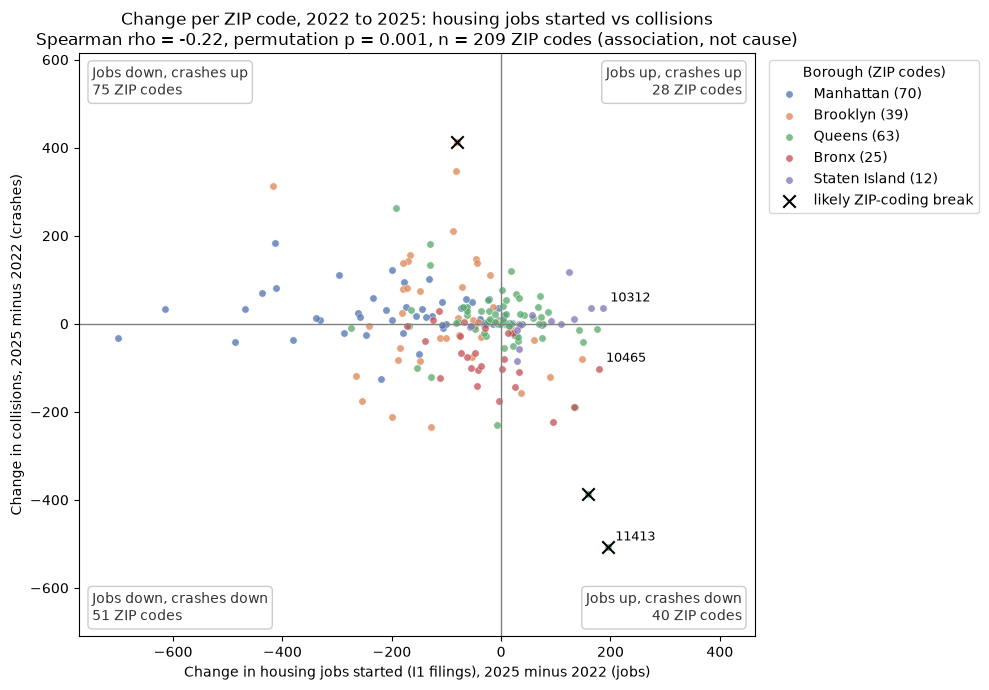

Saved assets/rq/issa_q1.png


In [3]:
fig, ax = plt.subplots(figsize=(10, 7))
for b in BOROUGHS:
    d = q1[q1["borough"] == b]
    ax.scatter(d["jobs_change"], d["crash_change"], s=28, alpha=0.75, color=BOROUGH_COLORS[b],
               label=f"{b} ({len(d)})", edgecolor="white", linewidth=0.4)
ax.scatter(breaks["jobs_change"], breaks["crash_change"], marker="x", s=80, color="black", linewidth=1.5,
           label="likely ZIP-coding break", zorder=3)
ax.axhline(0, color="grey", linewidth=1)
ax.axvline(0, color="grey", linewidth=1)
# Pad the axes so the quadrant labels in the corners sit in empty space, not on top of points.
xr, yr = np.ptp(q1["jobs_change"]), np.ptp(q1["crash_change"])
ax.set_xlim(q1["jobs_change"].min() - 0.08 * xr, q1["jobs_change"].max() + 0.30 * xr)
ax.set_ylim(q1["crash_change"].min() - 0.22 * yr, q1["crash_change"].max() + 0.22 * yr)
corners = [(0.98, 0.98, "right", "top", "jobs up, crashes up"),
           (0.02, 0.98, "left", "top", "jobs down, crashes up"),
           (0.02, 0.02, "left", "bottom", "jobs down, crashes down"),
           (0.98, 0.02, "right", "bottom", "jobs up, crashes down")]
for cx, cy, ha, va, key in corners:
    ax.text(cx, cy, f"{key.capitalize()}\n{quadrants[key]} ZIP codes", transform=ax.transAxes,
            ha=ha, va=va, fontsize=10, color="#333333",
            bbox=dict(boxstyle="round,pad=0.3", facecolor="white", edgecolor="#cccccc"))
for zip_code, row in top.head(3).iterrows():
    ax.annotate(zip_code, (row["jobs_change"], row["crash_change"]), xytext=(5, 5),
                textcoords="offset points", fontsize=9)
ax.set_title(f"Change per ZIP code, {START} to {END}: housing jobs started vs collisions\n"
             f"Spearman rho = {rho:.2f}, permutation p = {p:.3f}, n = {len(q1)} ZIP codes (association, not cause)")
ax.set_xlabel(f"Change in housing jobs started (I1 filings), {END} minus {START} (jobs)")
ax.set_ylabel(f"Change in collisions, {END} minus {START} (crashes)")
ax.legend(title="Borough (ZIP codes)", loc="upper left", bbox_to_anchor=(1.01, 1))
plt.tight_layout()
fig.savefig(ASSETS / "issa_q1.png", dpi=150, bbox_inches="tight")
plt.show()
print("Saved", ASSETS / "issa_q1.png")

In [4]:
direction = "positive" if rho > 0 else "negative"
strength = "very weak" if abs(rho) < 0.1 else "weak" if abs(rho) < 0.3 else "moderate" if abs(rho) < 0.5 else "strong"
top_boroughs = top["borough"].value_counts()
q1_finding = (
    f"Across the {len(q1)} NYC ZIP codes with enough data in both {START} and {END}, the change in housing jobs "
    f"started (I1 filings) and the change in ZIP-coded collisions have a Spearman rank correlation of {rho:.2f} "
    f"(permutation p = {p:.3f}), a {strength} {direction} association: ZIP codes where construction grew tended, "
    f"if anything, to see collisions fall slightly. "
    f"The fastest growth was concentrated in {top_boroughs.index[0]} ({top_boroughs.iloc[0]} of the top 10 ZIP codes). "
    f"{quadrants['jobs up, crashes up']} ZIP codes saw both rise, {quadrants['jobs down, crashes down']} saw both fall, "
    f"{quadrants['jobs up, crashes down']} added jobs while crashes fell and {quadrants['jobs down, crashes up']} "
    f"lost jobs while crashes rose. Among the 10 ZIP codes where housing jobs grew most, collisions rose in "
    f"{int((top['crash_change'] > 0).sum())} and fell in {int((top['crash_change'] < 0).sum())}. "
    f"Using new buildings instead of all housing jobs gives rho = {rho_nb:.2f} (p = {p_nb:.3f}). "
    f"{len(breaks)} ZIP codes show likely breaks in how crashes were ZIP-coded (for example "
    f"{breaks.index[0]}: {breaks['crashes_start'].iloc[0]} crashes in {START}, {breaks['crashes_end'].iloc[0]} in {END}); "
    f"without them rho is {rho_nobreak:.2f} (p = {p_nobreak:.3f}). "
    f"This is an association only: crashes with no ZIP code (about {MISSING_ZIP_PCT['2022']:.0f}% in {START} and "
    f"{MISSING_ZIP_PCT['2025']:.0f}% in {END}) are excluded, so part of the collision change reflects better ZIP "
    f"coverage, and there is no traffic or population denominator."
)
(ASSETS / "issa_q1.md").write_text(q1_finding + "\n", encoding="utf-8")
print(q1_finding)
print()
print("Saved", ASSETS / "issa_q1.md")

Across the 209 NYC ZIP codes with enough data in both 2022 and 2025, the change in housing jobs started (I1 filings) and the change in ZIP-coded collisions have a Spearman rank correlation of -0.22 (permutation p = 0.001), a weak negative association: ZIP codes where construction grew tended, if anything, to see collisions fall slightly. The fastest growth was concentrated in Queens (6 of the top 10 ZIP codes). 28 ZIP codes saw both rise, 51 saw both fall, 40 added jobs while crashes fell and 75 lost jobs while crashes rose. Among the 10 ZIP codes where housing jobs grew most, collisions rose in 2 and fell in 8. Using new buildings instead of all housing jobs gives rho = -0.14 (p = 0.045). 3 ZIP codes show likely breaks in how crashes were ZIP-coded (for example 11216: 247 crashes in 2022, 659 in 2025); without them rho is -0.19 (p = 0.007). This is an association only: crashes with no ZIP code (about 34% in 2022 and 20% in 2025) are excluded, so part of the collision change reflects b

### Q1 finding
Across the 209 NYC ZIP codes with enough data in both 2022 and 2025, the change in housing jobs started (I1 filings) and the change in ZIP-coded collisions have a Spearman rank correlation of -0.22 (permutation p = 0.001), a weak negative association: ZIP codes where construction grew tended, if anything, to see collisions fall slightly. The fastest growth was concentrated in Queens (6 of the top 10 ZIP codes). 28 ZIP codes saw both rise, 51 saw both fall, 40 added jobs while crashes fell and 75 lost jobs while crashes rose. Among the 10 ZIP codes where housing jobs grew most, collisions rose in 2 and fell in 8. Using new buildings instead of all housing jobs gives rho = -0.14 (p = 0.045). 3 ZIP codes show likely breaks in how crashes were ZIP-coded (for example 11216: 247 crashes in 2022, 659 in 2025); without them rho is -0.19 (p = 0.007). This is an association only: crashes with no ZIP code (about 34% in 2022 and 20% in 2025) are excluded, so part of the collision change reflects better ZIP coverage, and there is no traffic or population denominator.

### Q1 limitations
- **Missing ZIP codes:** crashes with no ZIP code are not in the table: about 33.83% of crashes in 2022 and 19.98% in 2025 (quoted from Yassin's notebook, printed above). Because coverage improved between the two years, part of each ZIP code's collision *increase* may be better ZIP coding rather than more crashes.
- **ZIP-coding breaks:** some ZIP codes' collision counts jump or collapse between years in a way that points to a change in how crashes were assigned a ZIP code, not to a real change (printed above). The result is shown with and without them.
- **No denominators:** there is no traffic volume or population, so a change in counts is not a change in risk.
- **Busy areas have more of both:** ZIP codes with more activity tend to have more building and more traffic. A shared trend can come from that rather than from construction itself.
- **ZIP codes are not neighbourhoods:** they differ a lot in size and land use.
- **Two endpoints:** a change between two years is sensitive to one unusual year. 2026 is left out because it is a partial year (January to October).

## Q2. Does the borough pattern of construction match the borough pattern of collisions over time?

**Why it matters to New Yorkers.** City budgets for street safety and for building inspection are often split by borough. If a borough's share of the city's crashes is much larger than its share of the city's construction, its crash burden is not explained by building activity, and the reverse also holds. Watching the gap over the years shows whether the boroughs are converging or drifting apart.

**Method.**
- For each borough and full year (2022 to 2025), add up housing jobs and collisions over its ZIP codes (low-data rows left out).
- Turn each into a **share of the city total** for that year, in percent.
- The heatmap shows **collision share minus housing share**, in percentage points. A positive (red) cell means the borough has a larger share of the city's crashes than of its construction; a negative (blue) cell means the reverse.

**Alternatives rejected.**
- *Raw counts per borough*: they mostly show which borough is biggest, and they move with citywide ups and downs. Shares remove both effects, so only the borough pattern is left.
- *Per-capita rates*: the project has no population data, and adding a third dataset is out of scope.
- *A ratio of the two shares*: unstable for a borough with a small share (Staten Island), while a difference in percentage points stays readable.

**Why a diverging heatmap.** Borough x year is a small grid, and the question is about the *sign and size of a gap*. A diverging colour scale centred on 0 shows at a glance which boroughs are above or below parity and whether that changes over time. The exact values are written in each cell.

In [5]:
by_borough = data.groupby(["borough", "year"])[["housing_job_count", "collision_count"]].sum()
shares = by_borough / by_borough.groupby("year").transform("sum") * 100
gap = (shares["collision_count"] - shares["housing_job_count"]).unstack("year").reindex(BOROUGHS)
housing_share = shares["housing_job_count"].unstack("year").reindex(BOROUGHS)
collision_share = shares["collision_count"].unstack("year").reindex(BOROUGHS)

print("Share of the city's housing jobs (%):")
print(housing_share.round(1).to_string())
print()
print("Share of the city's collisions (%):")
print(collision_share.round(1).to_string())
print()
print("Collision share minus housing share (percentage points):")
print(gap.round(1).to_string())
print()
summary_q2 = pd.DataFrame({
    "mean gap (pp)": gap.mean(axis=1).round(1),
    "min (pp)": gap.min(axis=1).round(1),
    "max (pp)": gap.max(axis=1).round(1),
    f"change {START}->{END} (pp)": (gap[END] - gap[START]).round(1),
    "same sign every year": (np.sign(gap).nunique(axis=1) == 1),
})
print(summary_q2.to_string())
assert np.allclose(gap.sum(axis=0), 0), "shares must add up to 100% on both sides"

Share of the city's housing jobs (%):
year           2022  2023  2024  2025
borough                              
Manhattan      43.2  43.2  38.2  38.3
Brooklyn       25.7  24.6  24.8  24.9
Queens         17.7  18.2  21.2  20.6
Bronx           9.2   8.9  10.0   9.9
Staten Island   4.2   5.1   5.8   6.2

Share of the city's collisions (%):
year           2022  2023  2024  2025
borough                              
Manhattan      17.4  17.9  18.2  19.0
Brooklyn       34.0  34.9  35.0  35.6
Queens         26.8  27.0  27.3  26.3
Bronx          17.9  16.0  15.4  15.1
Staten Island   4.0   4.1   4.1   4.1

Collision share minus housing share (percentage points):
year           2022  2023  2024  2025
borough                              
Manhattan     -25.8 -25.3 -20.0 -19.2
Brooklyn        8.4  10.2  10.2  10.6
Queens          9.1   8.9   6.1   5.6
Bronx           8.6   7.1   5.4   5.1
Staten Island  -0.3  -0.9  -1.7  -2.1

               mean gap (pp)  min (pp)  max (pp)  change 2022->2025 

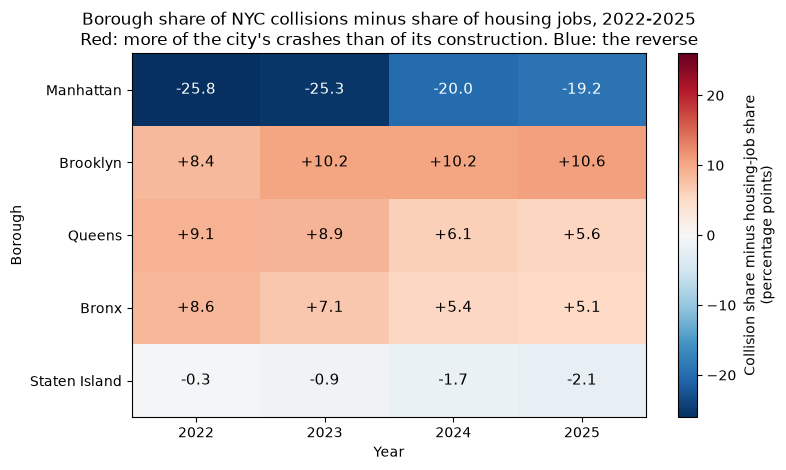

Saved assets/rq/issa_q2.png


In [6]:
limit = float(np.ceil(np.abs(gap.to_numpy()).max()))
fig, ax = plt.subplots(figsize=(8, 4.8))
im = ax.imshow(gap.to_numpy(), cmap="RdBu_r", norm=TwoSlopeNorm(vmin=-limit, vcenter=0, vmax=limit), aspect="auto")
ax.set_xticks(range(len(gap.columns)), [str(y) for y in gap.columns])
ax.set_yticks(range(len(gap.index)), gap.index)
for i in range(gap.shape[0]):
    for j in range(gap.shape[1]):
        v = gap.iat[i, j]
        ax.text(j, i, f"{v:+.1f}", ha="center", va="center", fontsize=11,
                color="white" if abs(v) > limit * 0.6 else "black")
cbar = fig.colorbar(im, ax=ax)
cbar.set_label("Collision share minus housing-job share\n(percentage points)")
ax.set_title(f"Borough share of NYC collisions minus share of housing jobs, {START}-{END}\n"
             "Red: more of the city's crashes than of its construction. Blue: the reverse")
ax.set_xlabel("Year")
ax.set_ylabel("Borough")
plt.tight_layout()
fig.savefig(ASSETS / "issa_q2.png", dpi=150, bbox_inches="tight")
plt.show()
print("Saved", ASSETS / "issa_q2.png")

In [7]:
most_pos = summary_q2["mean gap (pp)"].idxmax()
most_neg = summary_q2["mean gap (pp)"].idxmin()
stable = summary_q2["same sign every year"].sum()
q2_finding = (
    f"From {START} to {END}, the borough pattern of construction does not match the borough pattern of collisions. "
    f"{most_pos} has the largest positive gap: its share of the city's ZIP-coded collisions is on average "
    f"{summary_q2.loc[most_pos, 'mean gap (pp)']:.1f} percentage points higher than its share of housing jobs started. "
    f"{most_neg} has the largest negative gap ({summary_q2.loc[most_neg, 'mean gap (pp)']:.1f} points): it accounts for "
    f"a much larger share of construction than of crashes. "
    f"In {stable} of the 5 boroughs the gap has the same sign in every year, so the pattern is stable over time "
    f"rather than a one-year effect. "
    f"This is an association only: shares count only crashes with a ZIP code (missing ZIP codes fell from about "
    f"{MISSING_ZIP_PCT['2022']:.0f}% in {START} to {MISSING_ZIP_PCT['2025']:.0f}% in {END}), and there is no traffic or "
    f"population denominator, so a gap can reflect how many people drive through a borough rather than how much is built there."
)
(ASSETS / "issa_q2.md").write_text(q2_finding + "\n", encoding="utf-8")
print(q2_finding)
print()
print("Saved", ASSETS / "issa_q2.md")

From 2022 to 2025, the borough pattern of construction does not match the borough pattern of collisions. Brooklyn has the largest positive gap: its share of the city's ZIP-coded collisions is on average 9.9 percentage points higher than its share of housing jobs started. Manhattan has the largest negative gap (-22.6 points): it accounts for a much larger share of construction than of crashes. In 5 of the 5 boroughs the gap has the same sign in every year, so the pattern is stable over time rather than a one-year effect. This is an association only: shares count only crashes with a ZIP code (missing ZIP codes fell from about 34% in 2022 to 20% in 2025), and there is no traffic or population denominator, so a gap can reflect how many people drive through a borough rather than how much is built there.

Saved assets/rq/issa_q2.md


### Q2 finding
From 2022 to 2025, the borough pattern of construction does not match the borough pattern of collisions. Brooklyn has the largest positive gap: its share of the city's ZIP-coded collisions is on average 9.9 percentage points higher than its share of housing jobs started. Manhattan has the largest negative gap (-22.6 points): it accounts for a much larger share of construction than of crashes. In 5 of the 5 boroughs the gap has the same sign in every year, so the pattern is stable over time rather than a one-year effect. This is an association only: shares count only crashes with a ZIP code (missing ZIP codes fell from about 34% in 2022 to 20% in 2025), and there is no traffic or population denominator, so a gap can reflect how many people drive through a borough rather than how much is built there.

### Q2 limitations
- **Missing ZIP codes:** shares count only crashes with a ZIP code. About 33.83% of crashes in 2022 and 19.98% in 2025 had none (quoted from Yassin's notebook, printed above). If missing ZIP codes are more common in some boroughs, their collision shares are understated.
- **No denominators:** there is no traffic volume or population. A borough that many people drive *through* (for example to reach bridges and highways) can have a large share of crashes without much construction.
- **ZIP-coding breaks:** the breaks found in Q1 also move borough shares a little (two of them are in Queens).
- **Busy areas have more of both:** shares remove city-wide trends but not differences in how busy each borough is.
- **ZIP codes are not neighbourhoods,** and a borough is assigned to each ZIP code by its most frequent borough label.
- **2026 left out:** January to October only.

## Contribution note
Mohamed Issa authored the housing initial cleaning (`phase1_housing_initial_cleaning_issa.ipynb`), the integration and post-join cleaning (`phase2_data_integration_issa.ipynb`, which writes `data/zip_year.csv`), and these two research questions.

## Prompts used
Full log in `AI_PROMPTS.txt` (entries by Mohamed Issa).

AI-assisted cells:
- **Claude Code:** wrote this notebook from the team lead's "Issa 2" task: the metric choice for Q1 after the sparsity check, Spearman as the Pearson correlation of ranks with a permutation p-value, the borough share gap for Q2, both charts, and the generated finding paragraphs. The decisions were checked against the printed outputs.